In [5]:
import numpy as np
import matplotlib.pyplot as plt

In [6]:
# Função de custo(ex: função quadrática)
def funcao_custo(w):
    return w**2 -4*w +4 #Parábola

# Derivada da função de custo
def derivada_custo(w):
    return 2*w -4

# Implementação do gradiente descendente
eta = 0.1  # Taxa de aprendizado
w = 10    # Valor inicial de w
num_inter = 20  # Número de iterações

histórico = []

for i in range(num_inter):
    gradiente = derivada_custo(w)
    w = w - eta * gradiente
    histórico.append(w)
    print(f"Iteração {i+1}: w = {w:.4f}, Custo = {funcao_custo(w):.4f}")

Iteração 1: w = 8.4000, Custo = 40.9600
Iteração 2: w = 7.1200, Custo = 26.2144
Iteração 3: w = 6.0960, Custo = 16.7772
Iteração 4: w = 5.2768, Custo = 10.7374
Iteração 5: w = 4.6214, Custo = 6.8719
Iteração 6: w = 4.0972, Custo = 4.3980
Iteração 7: w = 3.6777, Custo = 2.8147
Iteração 8: w = 3.3422, Custo = 1.8014
Iteração 9: w = 3.0737, Custo = 1.1529
Iteração 10: w = 2.8590, Custo = 0.7379
Iteração 11: w = 2.6872, Custo = 0.4722
Iteração 12: w = 2.5498, Custo = 0.3022
Iteração 13: w = 2.4398, Custo = 0.1934
Iteração 14: w = 2.3518, Custo = 0.1238
Iteração 15: w = 2.2815, Custo = 0.0792
Iteração 16: w = 2.2252, Custo = 0.0507
Iteração 17: w = 2.1801, Custo = 0.0325
Iteração 18: w = 2.1441, Custo = 0.0208
Iteração 19: w = 2.1153, Custo = 0.0133
Iteração 20: w = 2.0922, Custo = 0.0085


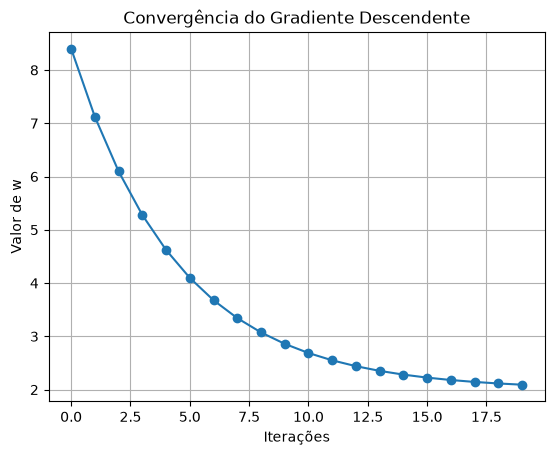

In [7]:
# plotando a convergência do peso
plt.plot(histórico, marker='o', linestyle='-')
plt.xlabel('Iterações')
plt.ylabel('Valor de w')
plt.title('Convergência do Gradiente Descendente')
plt.grid(True)
plt.show()

### Stochastic Gradient (SGD) ###
SGD atualiza os pesos apenas 1 amostra por vez, fica mais rápido e eficiente, mas deixa aleatório.

In [8]:
import tensorflow as tf
from tensorflow.keras.optimizers import SGD

modelo = tf.keras.Sequential([
    tf.keras.layers.Dense(1, input_shape=(1,))
])

modelo.compile(optimizer=SGD(learning_rate=0.01), loss='mse')

ModuleNotFoundError: No module named 'tensorflow'

### RMSprop ###
Ajusta a taxa de aprendizado p cada peso, evita explosão de gradiente (no Keras)

In [ ]:
from tensorflow.keras.optimizers import RMSprop

modelo.compile(optimizer=RMSprop(learning_rate=0.001), loss='mse')

ModuleNotFoundError: No module named 'tensorflow'

### ADAM (Adaptative Moment Estimation) ###
combina vantagens do Momentum e RMSprop

In [ ]:
from tensorflow.keras.optimizers import Adam

modelo.compile(optimizer=Adam(learning_rate=0.001), loss='mse')



### Exemplo Visual de Diferentes taxas de aprendizado ###

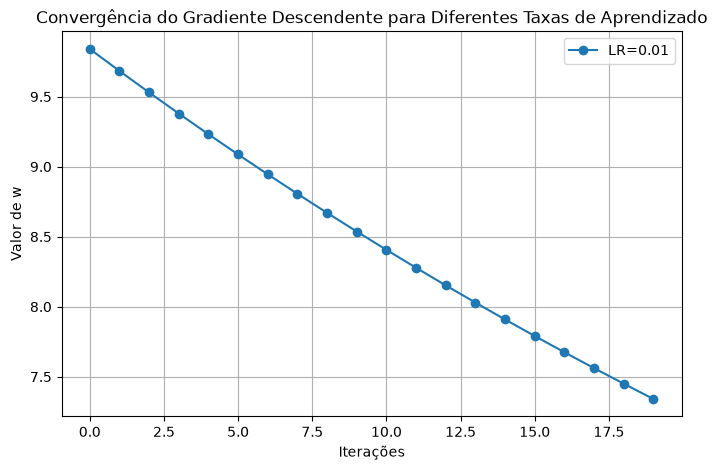

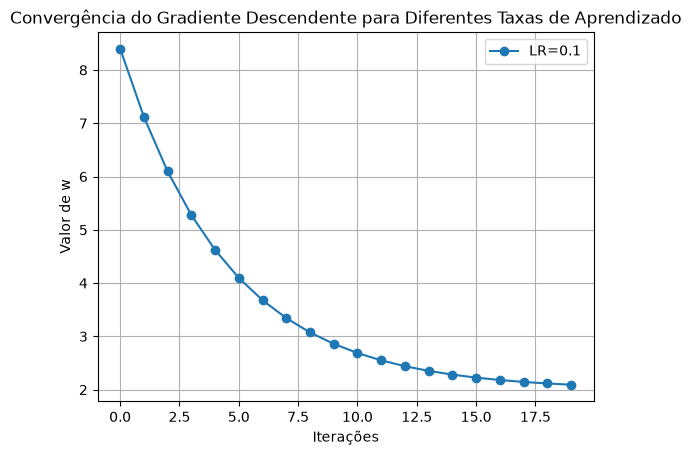

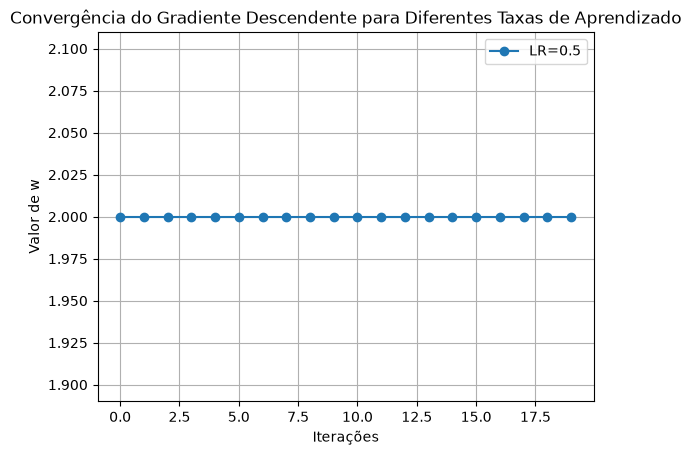

In [10]:
import numpy as np
import matplotlib.pyplot as plt

def derivada_custo(w):
    return 2*w - 4

def grad_desc(eta, num_iter=20):
    w = 10
    histórico = []
    
    for i in range(num_iter):
        gradiente = derivada_custo(w)
        w = w - eta * gradiente
        histórico.append(w)
    
    return histórico

etas = [0.01, 0.1, 0.5]
históricos = [grad_desc(eta) for eta in etas]

plt.figure(figsize=(8,5))
for i, eta in enumerate(etas):
    plt.plot(históricos[i], marker='o', linestyle='-', label=f'LR={eta}')
    plt.xlabel('Iterações')
    plt.ylabel('Valor de w')
    plt.title('Convergência do Gradiente Descendente para Diferentes Taxas de Aprendizado')
    plt.legend()
    plt.grid(True)
    plt.show()

### Métodos para ajuste do Learning Rate ###
Diminui o Learning Rate ao longo do tempo, ajudando a melhorar o resultado

In [ ]:
# Learning Rate Scheduling
lr_scheduler = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=0.1,
    decay_steps=1000,
    decay_rate=0.9
)

modelo.compile(optimizer=Adam(learning_rate=lr_scheduler), loss='mse')

NameError: name 'tf' is not defined

In [ ]:
# Cyclical Learning Rate (CLR) - ocila entre valor alto e baixo
import tensorflow_addons as tfa

clr = tfa.optimizers.CyclicalLearningRate(
    initial_learning_rate=0.001,
    maximal_learning_rate=0.006,
    step_size=2000,
    scale_fn=lambda x: 1/(2.0 **(x-1)),
    scale_mode='cycle'
)

modelo.compile(optimizer=Adam(learning_rate=clr), loss='mse')

In [ ]:
# Warmup - começa com uma LR baixa e vai aumentando gradualmente

class WarmupLearningRate(tf.keras.optimizers.schedules.LearningRateSchedule):
    def __init__(self, warmup_steps, peak_lr):
        self.warmup_steps = warmup_steps
        self.peak_lr = peak_lr

    def __call__(self, step):
        return self.peak_lr * (warmup_steps=1000, peak_lr=0.001)

modelo.compile(optimizer=Adam(learning_rate=Warmup_lr), loss='mse')